## This notebook demonstrates how to set up and use the Rainy-season Onset benchmarking package (HCWF)

It runs HCWF on the Ethiopia sample data (zarr stores of CHIRPS observations and AIFS forecasts) for one season, and shows what each step and each output looks like. It covers:
- an overview of the package structure and workflow
- how to install the package
- a notebook on how to prepare the config file
- the input data requirements
- how to run the package (command line and Python)
- the output data
- the metrics included in the package
- examples of the metric plots

Run it from the `docs/` folder with the data available as described under "Data preparation"; every output is written to `runs/` next to the notebook (ignored by version control, overwritten on a re-run).

<br>

### HCWF structure and workflow

<img src="HCWF_structure.png" width="490">

<br>

#### Benchmarking pipeline:  
1. Load configuration  
2. Setup benchmarking cases  
3. Read model and observation data  
4. Detect rainy season onset  
5. Evaluate model against reference  
6. Generate benchmarking metrics  
7. Save metric outputs and figures  
8. Make metric plots  

<br>

## Installation

Follow the installation steps in the repository [README](https://github.com/AI-Almanac/HCWF#readme) (also the quick start on the documentation front page) to install HCWF, and link a Jupyter kernel to your Python environment (`pip install ".[dev]"` installs Jupyter as well).

<br>

Initialize the notebook for the interactive demo.

In [1]:
# import necessary libraries for this demo
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
import xarray as xr
from IPython.display import Image, display

import hcwf
from hcwf.config.build import resolve
from hcwf.io.stores import open_data
from hcwf.naming import tuple_to_str


def rel(path):
    """Return a path relative to this notebook's folder (or to the data root), so no machine-specific folder is printed."""
    path = Path(path).resolve()
    for base, prefix in ((Path.cwd(), ""), (DATA.resolve(), "$HCWF_DEMO_DATA/")):
        if path == base or base in path.parents:
            return prefix + os.path.relpath(path, base)
    return path.name


def hcwf_run(*args):
    """Run `hcwf-run` as a command line does and print its output with the folders made relative."""
    done = subprocess.run([sys.executable, "-m", "hcwf.cli", *map(str, args)], capture_output=True, text=True)
    text = (done.stdout + done.stderr).replace(str(Path.cwd()) + "/", "").replace(str(DATA.resolve()), "$HCWF_DEMO_DATA").replace(str(DATA), "$HCWF_DEMO_DATA").replace("__main__.py", "hcwf-run")
    print(text.strip())

In [2]:
# the data root: HCWF_DEMO_DATA, else the nearest data/ folder above this notebook (it holds ethiopia/obs.zarr and ethiopia/models/)
DATA = Path(os.environ.get("HCWF_DEMO_DATA")
            or next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "ethiopia").is_dir())).expanduser()
os.environ["HCWF_DEMO_DATA"] = str(DATA)   # the config file spells its paths as ${HCWF_DEMO_DATA}/...

# tell HCWF which config file to use (the same as `hcwf-run -p`); here the one next to this notebook
config_path = Path("guidance_et.yaml").resolve()   # replace with your own edited copy
os.environ["HCWF_CONFIG"] = str(config_path)
rc = resolve(config_path)      # the validated run (a RunConfig), with both models

# the same config for each model: the deterministic AIFS, and the ensemble AIFS_ENS scored as probabilities
rc_det = resolve(config_path, {"model_list": ["AIFS"]})
rc_ens = resolve(config_path, {"model_list": ["AIFS_ENS"], "probabilistic": True})

In [3]:
# the HCWF package in use
try:
    from importlib.metadata import version
    print("HCWF version:", version("hcwf"))
except Exception:
    print("HCWF package:", hcwf.__name__)
print("config file is", rel(config_path))

HCWF version: 0.0.1
config file is guidance_et.yaml


<br>

## Set package configuration & benchmarking parameters

All parameters are set in a config file that you keep outside the package, given to HCWF with `-p` or the `HCWF_CONFIG` environment variable. Start from the template `examples/config.yaml`, or let `hcwf-run init` write one from your own files.

The config of this notebook is `guidance_et.yaml`, next to it. Its content:

In [4]:
# full package configurations & benchmarking parameters
text = Path(config_path).read_text()
print(text)

# Config of docs/package_run_guidance_et.ipynb: Ethiopia, one season, a deterministic and an ensemble AIFS.
# Paths start at the folder of this file; ${HCWF_DEMO_DATA} is the data root (the notebook sets it to the repository's
# data/ folder when it is not set). Copy this file and edit it for your own run.
project_name: Ethiopia guidance run

region: ethiopia

observations:
  path: ${HCWF_DEMO_DATA}/ethiopia/obs.zarr

models:
  - name: AIFS
    path: ${HCWF_DEMO_DATA}/ethiopia/models/AIFS_v2.zarr
    lead_label: start
  - name: AIFS_ENS
    path: ${HCWF_DEMO_DATA}/ethiopia/models/AIFS_ENS_v2.zarr
    lead_label: start

evaluation:
  start_date: [2020, 5, 1]       # forecasts issued 1 May - 31 Aug 2020
  end_date: [2020, 8, 31]
  verification_windows: [[1, 15]]
  tolerances: [3]
  max_forecast_day: 15
  day_bins: [[1, 5], [6, 10], [11, 15]]
  probabilistic: false           # true: the models' members give onset probabilities (the notebook runs AIFS_ENS this way)

output:                

<br>

Refer to the [package configuration instructions notebook](package_configuration.ipynb) to prepare for your config file    

<br>

## Data preparation

With the data root in mind, make sure the required input data are in place. This notebook reads the Ethiopia sample stores, which sit under one data root: the environment variable `HCWF_DEMO_DATA` if set, else the nearest `data/` folder above this notebook.

```
<data root>/ethiopia/obs.zarr
<data root>/ethiopia/models/{AIFS_v2,AIFS_ENS_v2,graphcast}.zarr
```

In [5]:
# retrieve the input data locations from the package configuration
print("observations path:", rel(rc.observations.dir))
print("models[] paths:", [rel(m.dir) for m in rc.models])

observations path: $HCWF_DEMO_DATA/ethiopia/obs.zarr
models[] paths: ['$HCWF_DEMO_DATA/ethiopia/models/AIFS_v2.zarr', '$HCWF_DEMO_DATA/ethiopia/models/AIFS_ENS_v2.zarr']


Required data include
- **forecast model**
- **observation (ground truth)**
- a **reference** (here the onset climatology, which HCWF builds from the observations; nothing to prepare)

An observation or forecast dataset is either one **zarr store** holding every year, or NetCDF files (one per year, named by the `file_pattern` key, in which `{}` stands for the year; or listed with `paths`). The notebook uses zarr stores, so `file_pattern` is not needed and the config only gives `path`; variable, units, dimension names, members and accumulation are detected from the store and reported by `hcwf-run -p guidance_et.yaml --check`.

In [6]:
# the stores in this run: dimensions and variables, read lazily (nothing is loaded)
for name, store in [("observations", rc.observations.dir)] + [(m.name, m.dir) for m in rc.models]:
    with open_data(store) as ds:
        print(f"{name:13s} {rel(store)}")
        print("   dimensions:", dict(ds.sizes))
        print("   variables :", list(ds.data_vars))

observations  $HCWF_DEMO_DATA/ethiopia/obs.zarr
   dimensions: {'time': 10227, 'latitude': 49, 'longitude': 61}
   variables : ['total_precipitation_24hr']
AIFS          $HCWF_DEMO_DATA/ethiopia/models/AIFS_v2.zarr
   dimensions: {'time': 1118, 'prediction_timedelta_daily': 50, 'lat': 49, 'lon': 61}
   variables : ['tp']
AIFS_ENS      $HCWF_DEMO_DATA/ethiopia/models/AIFS_ENS_v2.zarr
   dimensions: {'time': 1118, 'number': 26, 'prediction_timedelta_daily': 50, 'lat': 49, 'lon': 61}
   variables : ['tp']


The data must have the standard spatiotemporal dimensions: latitude `lat` and longitude `lon` (also `latitude`/`longitude`), the forecast initialization time `time` or `init_time`, and the forecast step `step` (or `day`; here `prediction_timedelta_daily`, a lead in days). Observations have `time` and the grid only. Ensemble forecasts have an additional ensemble dimension, `ensemble`, `member` or `number` (here `number`, with 26 members). Other names can be given with the `dims` key of the dataset.

Valid format and dimensions of the input data (the deterministic model, then the ensemble) look like the output above.

<br>

## Run the HCWF benchmarking package

#### HCWF supports two operational modes:
- **Production mode**: Executed via the command line interface (CLI) for standard workflows and automated pipelines.
- **Research mode**: Accessible as an importable Python module, enabling interactive experimentation, analysis, and integration within Python scripts or Jupyter notebooks.


### 1 - &nbsp;Run HCWF in **production mode**
With a properly configured config file, the main benchmarking workflow is executed via the CLI:

`hcwf-run -p my_config.yaml`

Typical steps performed:
1. Load configuration
2. Set up benchmarking cases
3. Read model and observation data
4. Detect rainy season onset
5. Evaluate model against reference data
6. Generate benchmarking metrics
7. Save metric outputs and figures
8. Make metric plots

With all parameters and flags properly configured, run HCWF, and pay attention to the runtime console output.

The config lists a deterministic and an ensemble model, and probabilistic scoring is a setting of the whole run, so the two are run one after the other, choosing the model and the scoring with command-line options (`--overwrite` re-runs a run folder that already exists). First the deterministic AIFS (`--quiet` prints only warnings and errors):

In [7]:
hcwf_run("-p", config_path, "--model_list", "AIFS", "--overwrite", "--quiet")
print("run folder:", rel(rc_det.output.data_dir).rsplit("/", 1)[0])


run folder: runs/ethiopia_icpac_2020_604e


Then the ensemble AIFS_ENS, scored as probabilities (BSS, RPSS, AUC, reliability):

In [8]:
hcwf_run("-p", config_path, "--model_list", "AIFS_ENS", "--probabilistic", "True", "--overwrite")

  _   _   ____  __        __  _____
 | | | | / ___| \ \      / / |  ___|
 | |_| || |      \ \ /\ / /  | |_
 |  _  || |___    \ V  V /   |  _|
 |_| |_| \____|    \_/\_/    |_|

 Human-Centered Weather Forecasts (HCWF)
 Version : 0.0.1

--------------------------------------------------------------------------------
 Project    : Ethiopia guidance run
 Start Time : 2026-11-07T18:20:22
--------------------------------------------------------------------------------

 Initializing analysis pipeline...

Onset settings:
  Onset definition : icpac v1 (draft)  [region default (ethiopia)]
  Season           : main  [the definition's only season]
  Threshold years  : 1998-2024  [region default (ethiopia)]
  Day boundary     : 00 UTC, labelled by start  [region default (ethiopia)]
  Lead label       : start  [derived from obs_day_boundary]
  Dry-spell check  : on  [config dry_spell_check]
  Forecast history : observed  [default]
  Threshold source : observations  [default]
  Backend          : nu

<br>
<br>

Without `-p`, HCWF uses the config named by the `HCWF_CONFIG` environment variable, and stops if neither is set. To run another job, point `-p` at another file:

```
hcwf-run -p /path_to/config_job1.yaml
```

This works from the CLI. In a notebook or script, set `HCWF_CONFIG` before resolving the config.

A config file with a `blend:` section trains an onset blend instead of benchmarking, and `hcwf-run forecast` applies a trained blend to live forecasts; see [blending.md](blending.md).

<br>

A command-line option overrides a config value for one run, for quick sensitivity tests. Here the dry-spell condition of the onset definition is left out; `--check` resolves the config and prints the plan, without running anything, and records where each value came from (the run folder differs from the runs above because the setting differs):

In [9]:
# the same config with a command-line override (here, without the dry-spell check), checked but not run
hcwf_run("-p", config_path, "--model_list", "AIFS", "--dry_spell_check", "False", "--check")

HCWF check of Ethiopia guidance run: nothing will be run

== Settings ==
config file     : guidance_et.yaml
region          : ethiopia  [run config]
first date      : (2020, 5, 1)  [run config]
last date       : (2020, 8, 31)  [run config]
init weekdays   : (0, 3)  [default]
climatology from: 1998  [region default]
climatology to  : 2024  [region default]
lead windows    : ((1, 15),)  [run config]
tolerances (days): (3,)  [run config]
max forecast day: 15  [run config]
day bins        : ((1, 5), (6, 10), (11, 15))  [run config]
ensemble        : False  [run config]
members         : All  [default]
reference       : climatology  [default]
climatology_cv  : leave_one_year_out  [default]
ensemble onset share: 0.5  [default]
models          : AIFS
Onset definition : icpac v1 (draft), overridden: reject if (dry_spell_check = false)  [region default (ethiopia)]
Season           : main  [the definition's only season]
Threshold years  : 1998-2024  [region default (ethiopia)]
Day boundary     :

<br>

The package also supports passing specific parameter values via command-line options for quick sensitivity tests.  

for available CLI parameter and flag options, run `hcwf-run -p my_config.yaml -h`

In [10]:
hcwf_run("-p", config_path, "-h")

usage: hcwf-run [-h] [--model_list MODEL_LIST [MODEL_LIST ...]]
                   [--verification_window_list VERIFICATION_WINDOW_LIST]
                   [--max_forecast_day MAX_FORECAST_DAY]
                   [--dry_spell_check DRY_SPELL_CHECK]
                   [--forecast_history {observed,none}]
                   [--threshold_source {observations,model}]
                   [--onset_percentage_threshold ONSET_PERCENTAGE_THRESHOLD]
                   [--tolerance_days_list TOLERANCE_DAYS_LIST [TOLERANCE_DAYS_LIST ...]]
                   [--day_bins DAY_BINS]
                   [--start_date START_DATE START_DATE START_DATE]
                   [--end_date END_DATE END_DATE END_DATE]
                   [--show_plot SHOW_PLOT] [--show_panel SHOW_PANEL]
                   [--probabilistic PROBABILISTIC] [--parallel PARALLEL]
                   [--region REGION] [--check] [--alignment] [--overwrite]
                   [--quiet] [--verbose]

HCWF Package Parameter Loader

options:
  

<br>

### 2 - &nbsp;Run HCWF in **Research mode**
#### Option 1. Run the config from Python

```python
import hcwf
result = hcwf.run("my_config.yaml", max_forecast_day=15)   # overrides use the flat key names of the schema
result.observed, result.scores, result.forecasts          # xarray and pandas objects; nothing is written unless write=True
```

`hcwf.run(cfg, write=False, overwrite=False, quiet=False, **overrides)` takes a YAML path, a `Config` or a dict. Here the deterministic AIFS of this notebook, kept in memory:

In [11]:
result = hcwf.run(config_path, model_list=["AIFS"], quiet=True)   # nothing is written
print("scores:", list(result.scores))
result.scores["summary"].round(2)

scores: ['spatial', 'summary']


,model,window,mean_mae,false_alarm_rate,miss_rate
0,AIFS,1-15,18.38,0.19,0.57
1,climatology,1-15,21.23,0.32,0.44


<br>

#### Option 2. Import the diagnostic functions

`from hcwf.figures.notebook import obs_onset_analysis as ons`

and then write your own diagnostic code leveraging the `obs_onset_analysis()` functionality

<br>

Here is an example of using `obs_onset_analysis()` for diagnosing the rainy season onset of 2020 at a location in central Ethiopia (9 N, 38.75 E); the figure is also saved in the run's `figures/` folder

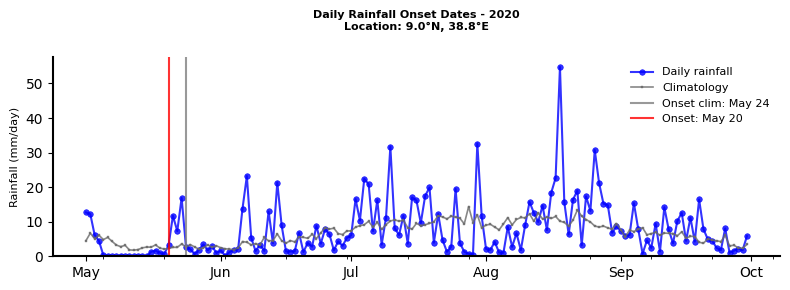

In [12]:
from hcwf.figures.notebook import obs_onset_analysis as ons
_ = ons(2020, rc_det, lat_select=9.0, lon_select=38.75)

<br>
<br>

## Metric Results

`output.data_dir` (the folder given in the config, or the `scores/` folder of the run folder `runs/<name>/` when it is left out, as here) tells where the package output data are located
spatial metrics are saved in `.nc` files
domain averaged probabilistic metrics are saved in `.csv` files

In [13]:
# benchmarking output data
for label, run in (("deterministic AIFS", rc_det), ("probabilistic AIFS_ENS", rc_ens)):
    dir_out = Path(run.output.data_dir)
    print(f"{label}: benchmarking metrics data in --> {rel(dir_out)}/")
    for path in sorted(dir_out.glob("*")):
        print("   ", path.name)

deterministic AIFS: benchmarking metrics data in --> runs/ethiopia_icpac_2020_604e/scores/
    climatology_onset.nc
    spatial_AIFS_1-15.nc
    spatial_climatology_1-15.nc
probabilistic AIFS_ENS: benchmarking metrics data in --> runs/ethiopia_icpac_2020_94fa/scores/
    binned_AIFS_ENS_1-15.csv
    climatology_onset.nc
    overall_AIFS_ENS_1-15.csv
    spatial_AIFS_ENS_1-15.nc
    spatial_climatology_1-15.nc


<br>

Below is an example of saved binned skill scores from the benchmarking of a probabilistic forecast

In [14]:
model_name = rc_ens.models[0].name
window = rc_ens.evaluation.windows[0].span
dir_out_ens = Path(rc_ens.output.data_dir)
filename = dir_out_ens / f"binned_{model_name}_{tuple_to_str(window)}.csv"
print("loading saved metrics from", rel(filename))
df_bins = pd.read_csv(filename)
df_bins

loading saved metrics from runs/ethiopia_icpac_2020_94fa/scores/binned_AIFS_ENS_1-15.csv


,Bin,clean_bins,Fair_Brier_Skill_Score,AUC,AUC_ref,Fair_Brier_Score_Forecast,Fair_Brier_Score_Climatology
0,Days 1-5,1-5,0.439754,0.743943,0.801113,0.046054,0.082203
1,Days 6-10,6-10,-0.226847,0.733633,0.751243,0.080929,0.065965
2,Days 11-15,11-15,-0.502816,0.685928,0.754067,0.089975,0.059871


<br>

metric plots are saved in the output figure folder as defined in `output.figure_dir`  

In [15]:
# metrics plots
dir_fig_ens = Path(rc_ens.output.figure_dir)
dir_fig_det = Path(rc_det.output.figure_dir)
for label, folder in (("probabilistic AIFS_ENS", dir_fig_ens), ("deterministic AIFS", dir_fig_det)):
    print(f"{label}: metrics plots in --> {rel(folder)}/")
    for path in sorted(folder.glob("*")):
        print("   ", path.name)

probabilistic AIFS_ENS: metrics plots in --> runs/ethiopia_icpac_2020_94fa/figures/
    panel_bar_BSS_RPSS_AUC_1-15.png
    panel_portrait_BSS_AUC_1-15.png
    reliability_AIFS_ENS_1-15.png
    skill_scores_heatmap_AIFS_ENS_1-15.png
    spatial_metrics_AIFS_ENS_1-15.png
    spatial_metrics_climatology_1-15.png
deterministic AIFS: metrics plots in --> runs/ethiopia_icpac_2020_604e/figures/
    onset_time_series_lat9.0_lon38.75_2020.png
    spatial_metrics_AIFS_1-15.png
    spatial_metrics_climatology_1-15.png


<br>

if `output.plot_heatmap_bss_auc` is `true`, it plots a heatmap of BSS and AUC

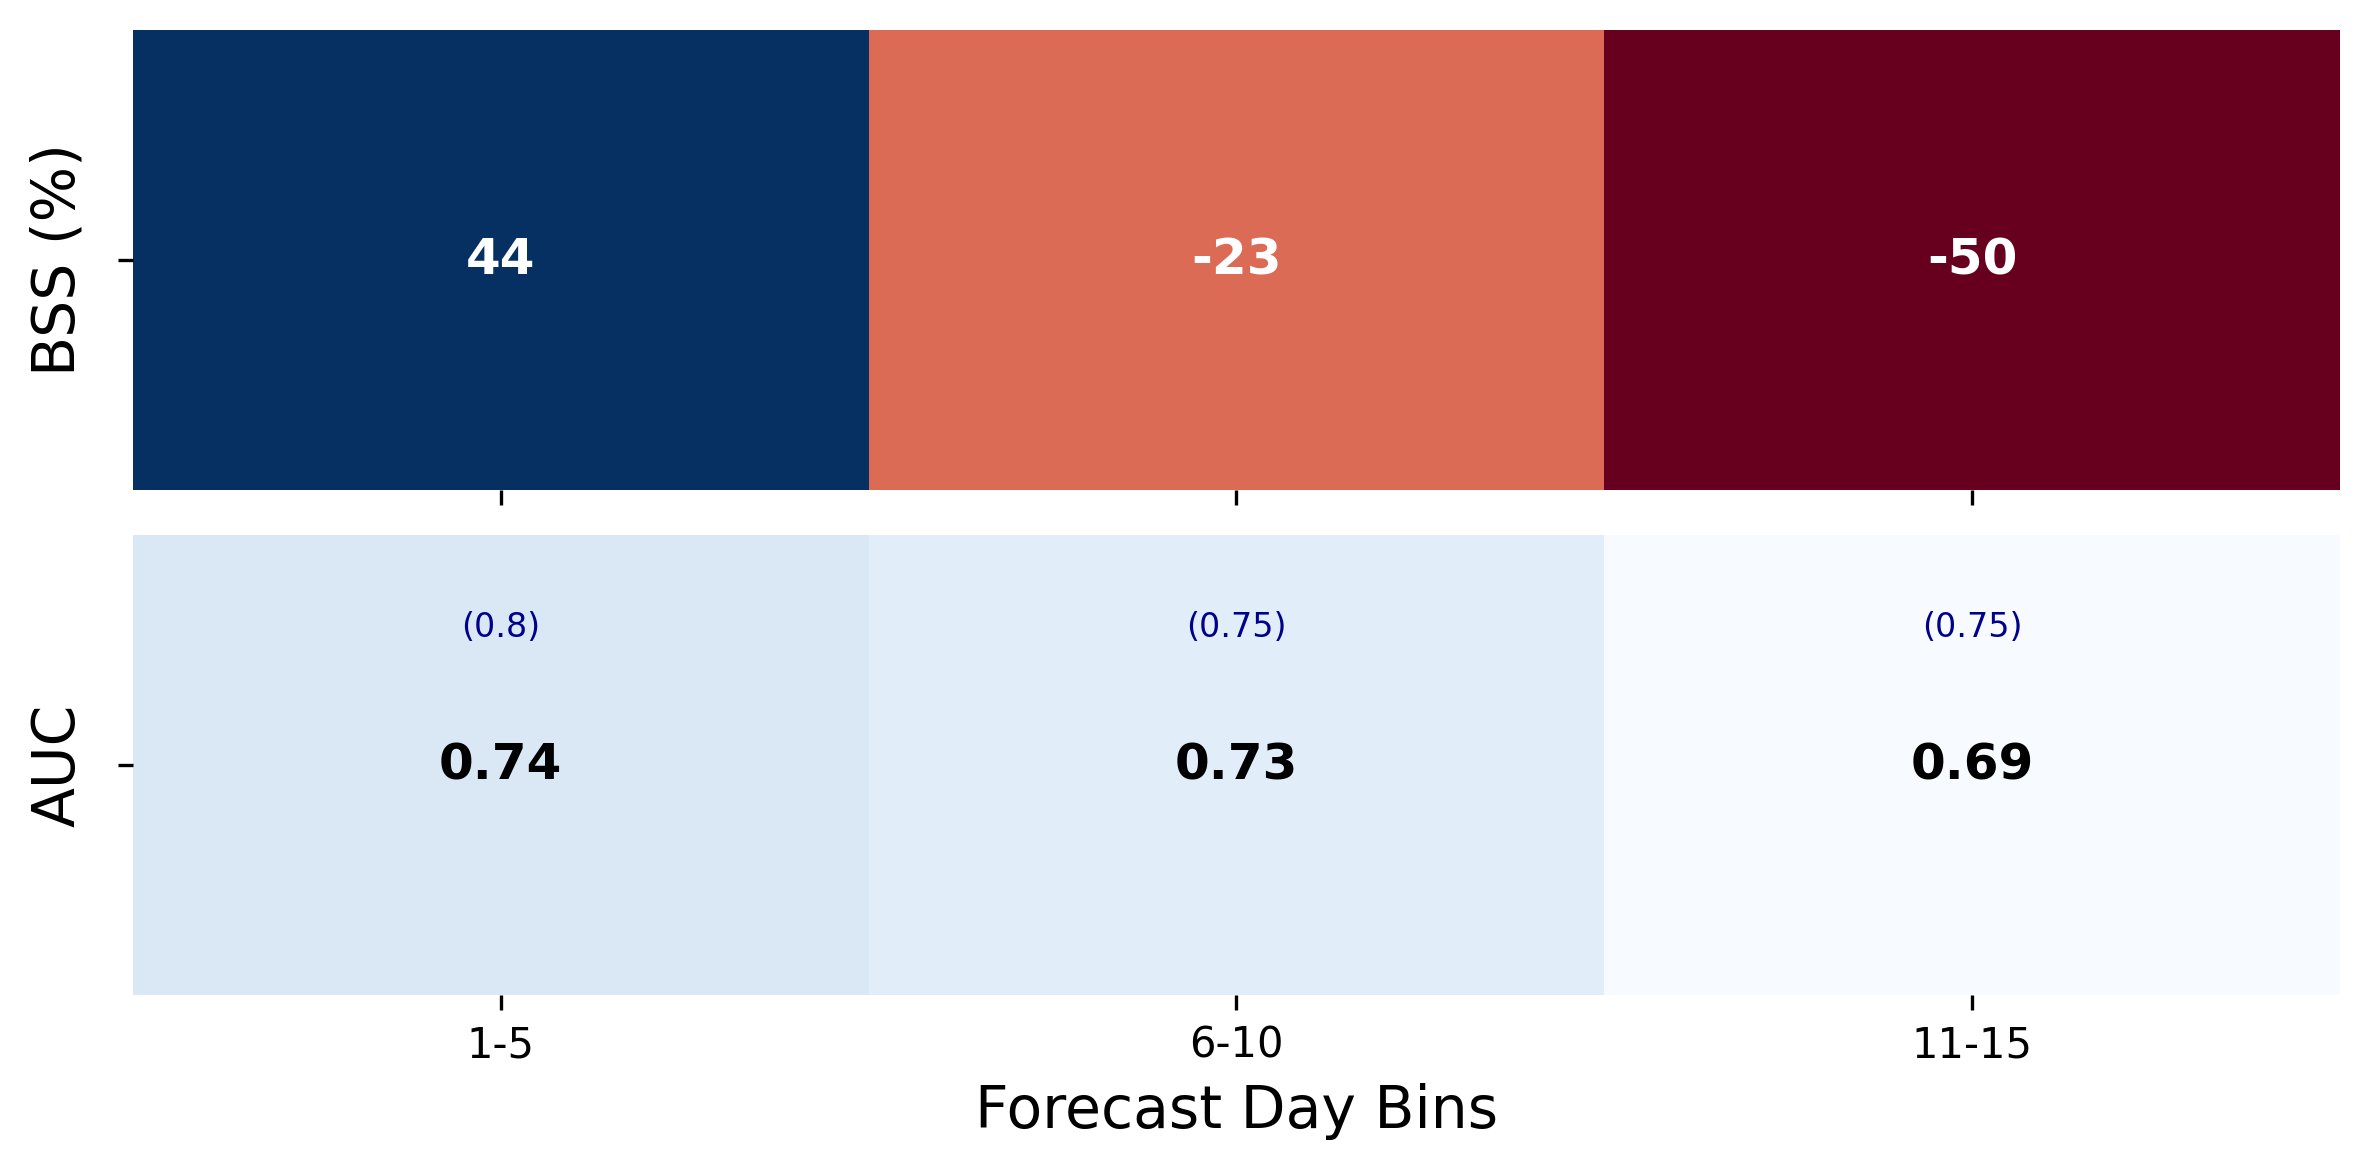

In [16]:
# Load the image from the run's figure folder
fig_filename = dir_fig_ens / f"skill_scores_heatmap_{model_name}_{tuple_to_str(window)}.png"
display(Image(filename=fig_filename, width=390))

<br>

Brier Skill Score (BSS) measures the relative improvement of a forecast compared to a reference forecast (climatology in this example)  

Think of the BSS as a percentage of improvement over "guessing" based on historical averages.

| Score | Meaning |
| :--- | :--- |
|1.0 | Perfect Forecast. You nailed the probability and the outcome every single time.
|> 0	|Skilled. You are performing better than the reference (climatology). The closer to 1, the better.
|0	|No Skill. You might as well have just looked up the historical average for that day; your model added zero value.
|< 0	|Worse than useless. Your forecast is actually performing worse than a simple long-term average. Time to recalibrate!   

<br>

Area Under the ROC (Receiver Operating Characteristic) Curve (AUC plots the Hit Rate (True Positive Rate) against the False Alarm Rate (False Positive Rate) for every possible probability threshold (0% to 100%). It tells you the probability that a randomly chosen "event" day was assigned a higher forecast probability than a randomly chosen "non-event" day.  

| AUC Value | Interpretation | Operational Reality |
| :--- | :--- | :--- |
| **1.0** | **Perfect Discrimination** | The "Golden Ticket." The model never ranks a dry day higher than a wet day. |
| **0.8 – 0.9** | **Excellent** | Very useful for automated alerts. High confidence in the model's "signal." |
| **0.7 – 0.8** | **Good/Fair** | Useful for general forecasting, but requires human oversight to filter noise. |
| **0.5** | **No Skill** | The model is effectively "guessing." It has zero ability to distinguish a storm from a clear sky. |
| **< 0.5** | **Worse than Random** | The model is consistently backward (e.g., it gives higher probabilities to dry days). |

<br>

<br>

if `output.plot_reliability` is `true`, it generates a reliability diagram

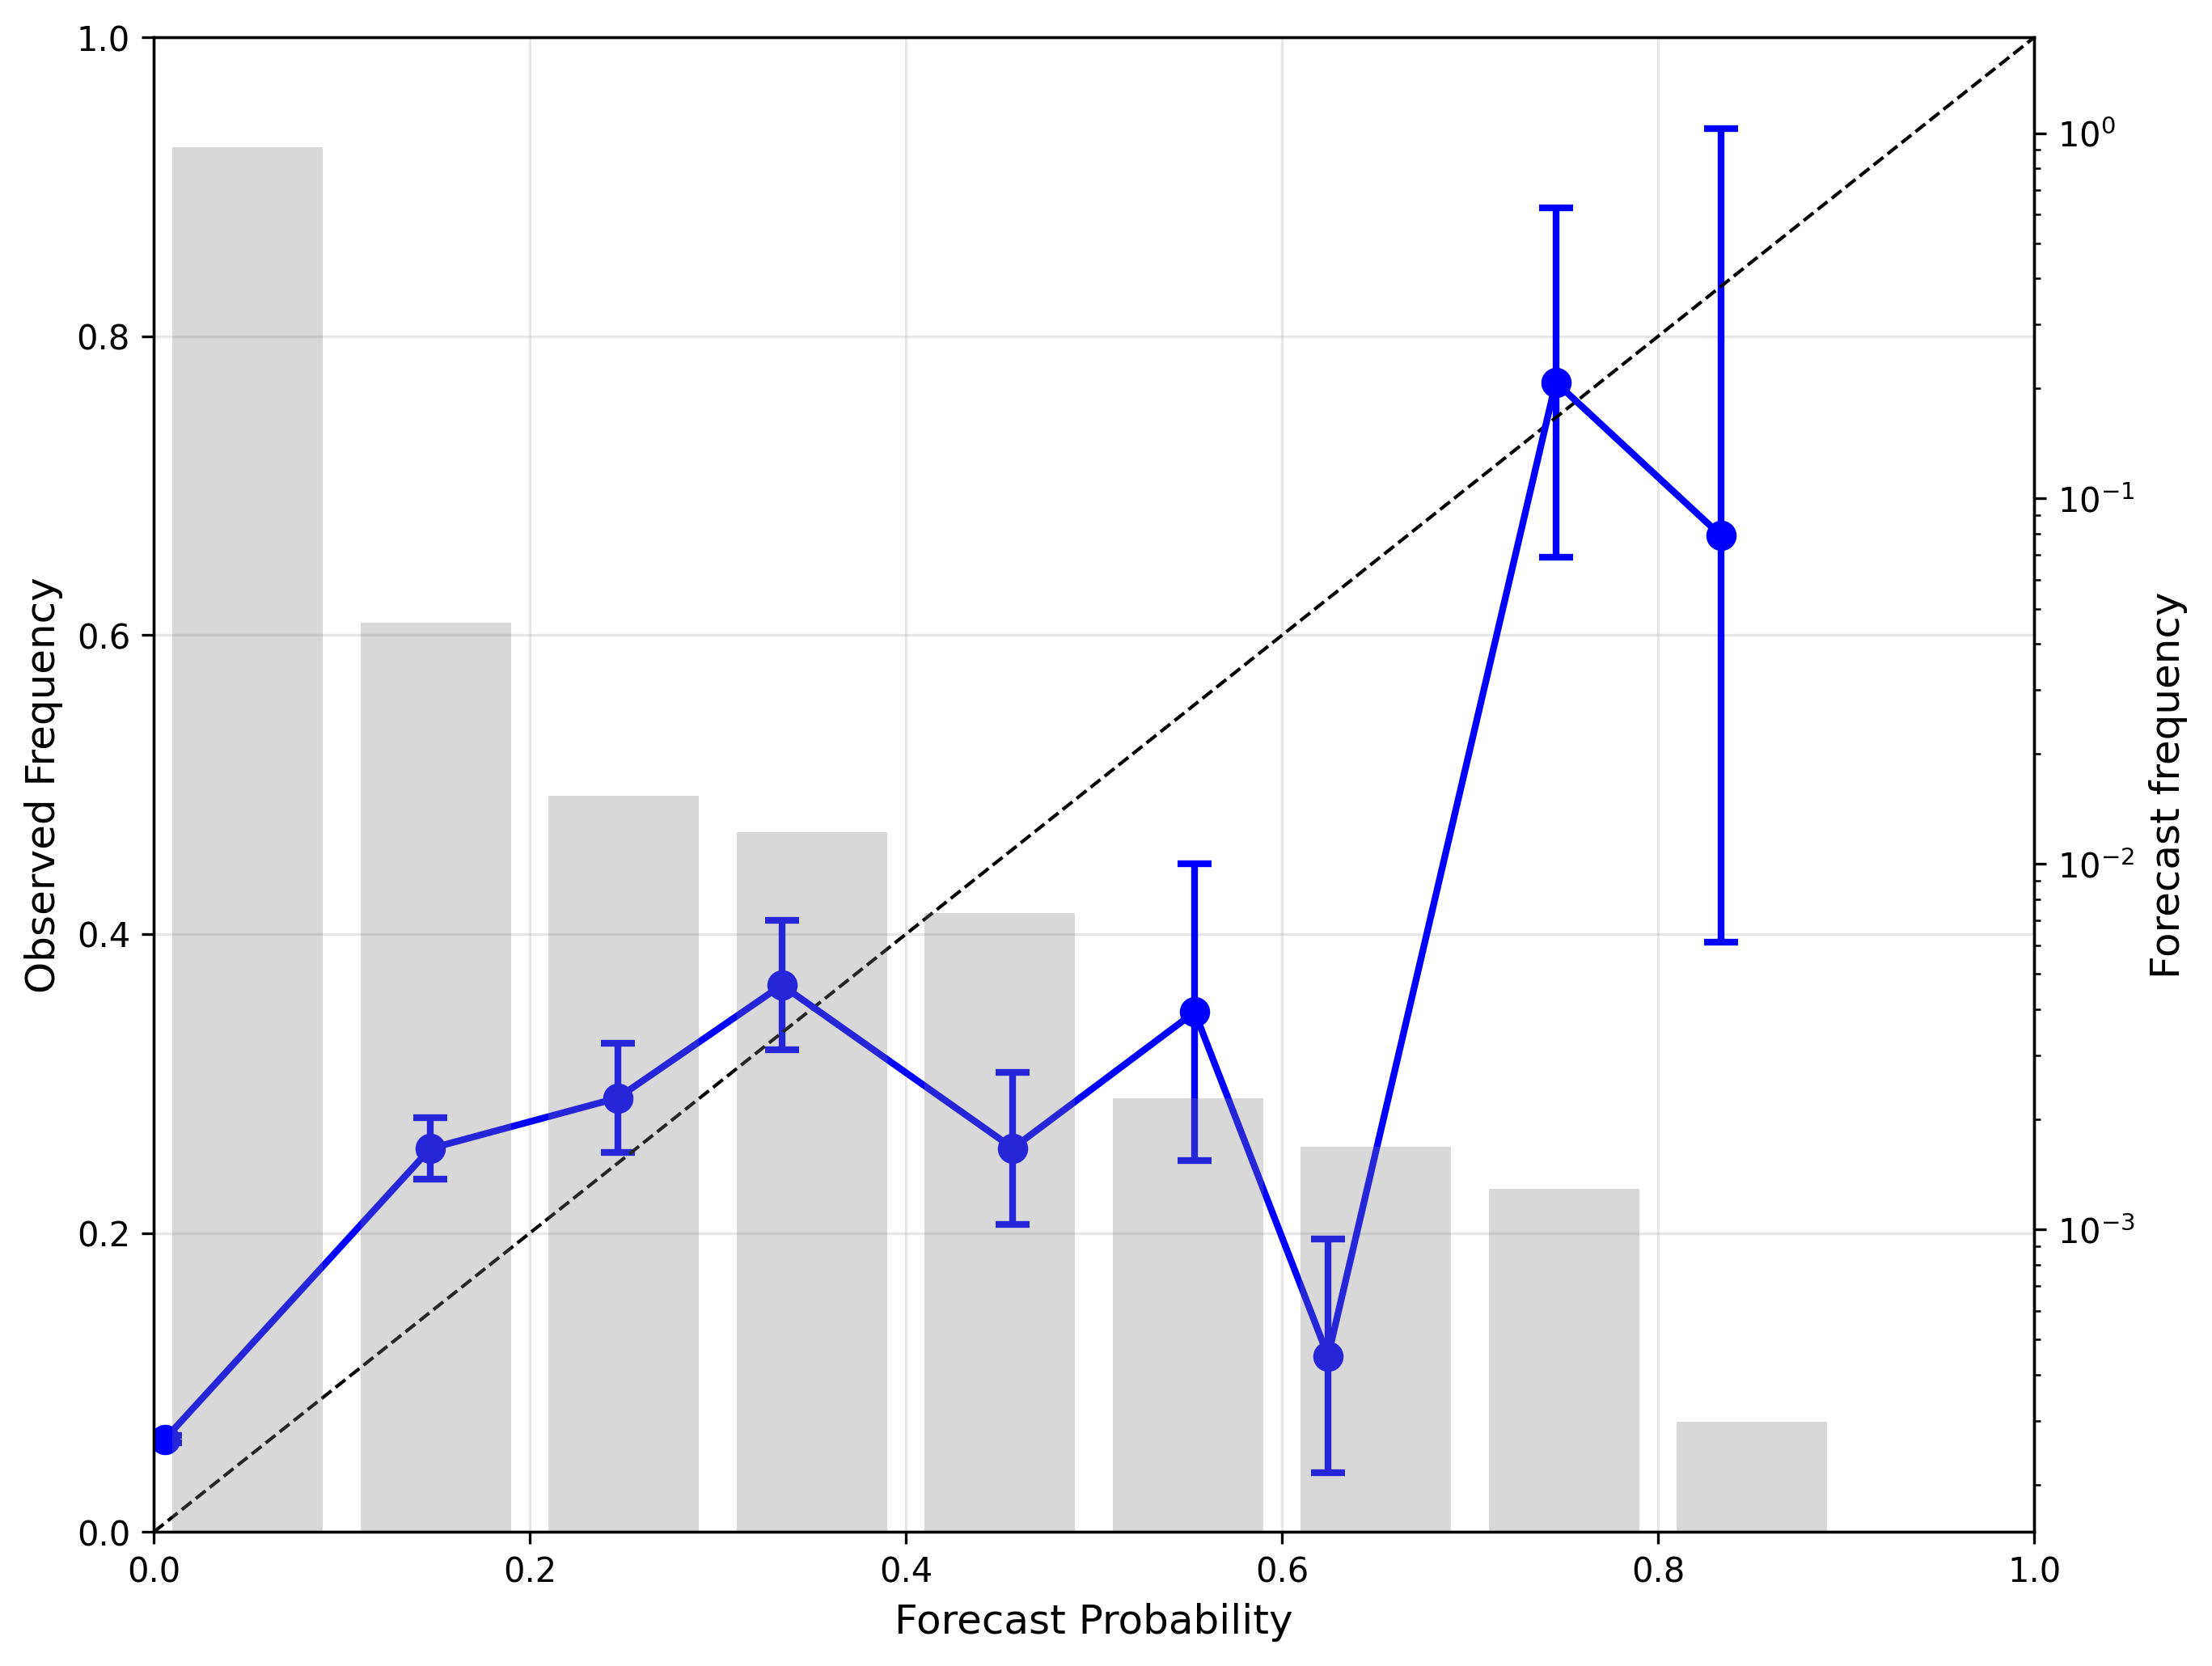

In [17]:
fig_filename = dir_fig_ens / f"reliability_{model_name}_{tuple_to_str(window)}.png"
display(Image(filename=fig_filename, width=390))

<br>

Reliability Diagram (also called an Attributes Diagram) is the "detailed feedback" that tells you exactly where a probabilistic model is failing or succeeding.  

The Diagonal (Dashed Line) represents Perfect Reliability. Along this line, the forecast probability exactly matches the observed frequency (e.g., when the model says "20%," it actually happens 20% of the time).  

The Blue Line (Reliability Curve) shows how your model actually performed.  

Error Bars represent the confidence interval (usually 95%). If the sample size in a specific probability bin is small, the error bars will be larger, meaning the data point is less statistically significant.

The Grey Bars (Refinement/Sharpness) is a histogram showing how often the model issued a specific probability.

Operationally: We want a "U-shaped" histogram (lots of 0% and 100% forecasts). If all the bars are in the middle (near climatology), the model is "unconfident."

| Position of Blue Line | Statistical Term | Operational Meaning |
| :--- | :--- | :--- |
| **Above the Diagonal** | **Under-forecasting** | The model is too "conservative." When it predicts 20%, the event happens 40% of the time. You should trust the model *more* than it suggests. |
| **Below the Diagonal** | **Over-forecasting** | The model is "crying wolf." When it predicts 80%, the event only happens 60% of the time. You should "dampen" its enthusiasm. |
| **Flatter than Diagonal** | **Over-confident** | The model moves toward 0% and 100% too aggressively, but reality stays closer to the middle. |
| **Steeper than Diagonal** | **Under-confident** | The model stays near the average, but reality is more extreme. |

<br>

<br>

if `output.plot_bar_bss_rpss_auc` is `true`, it generates a bar plot for metrics BSS, RPSS and AUC 

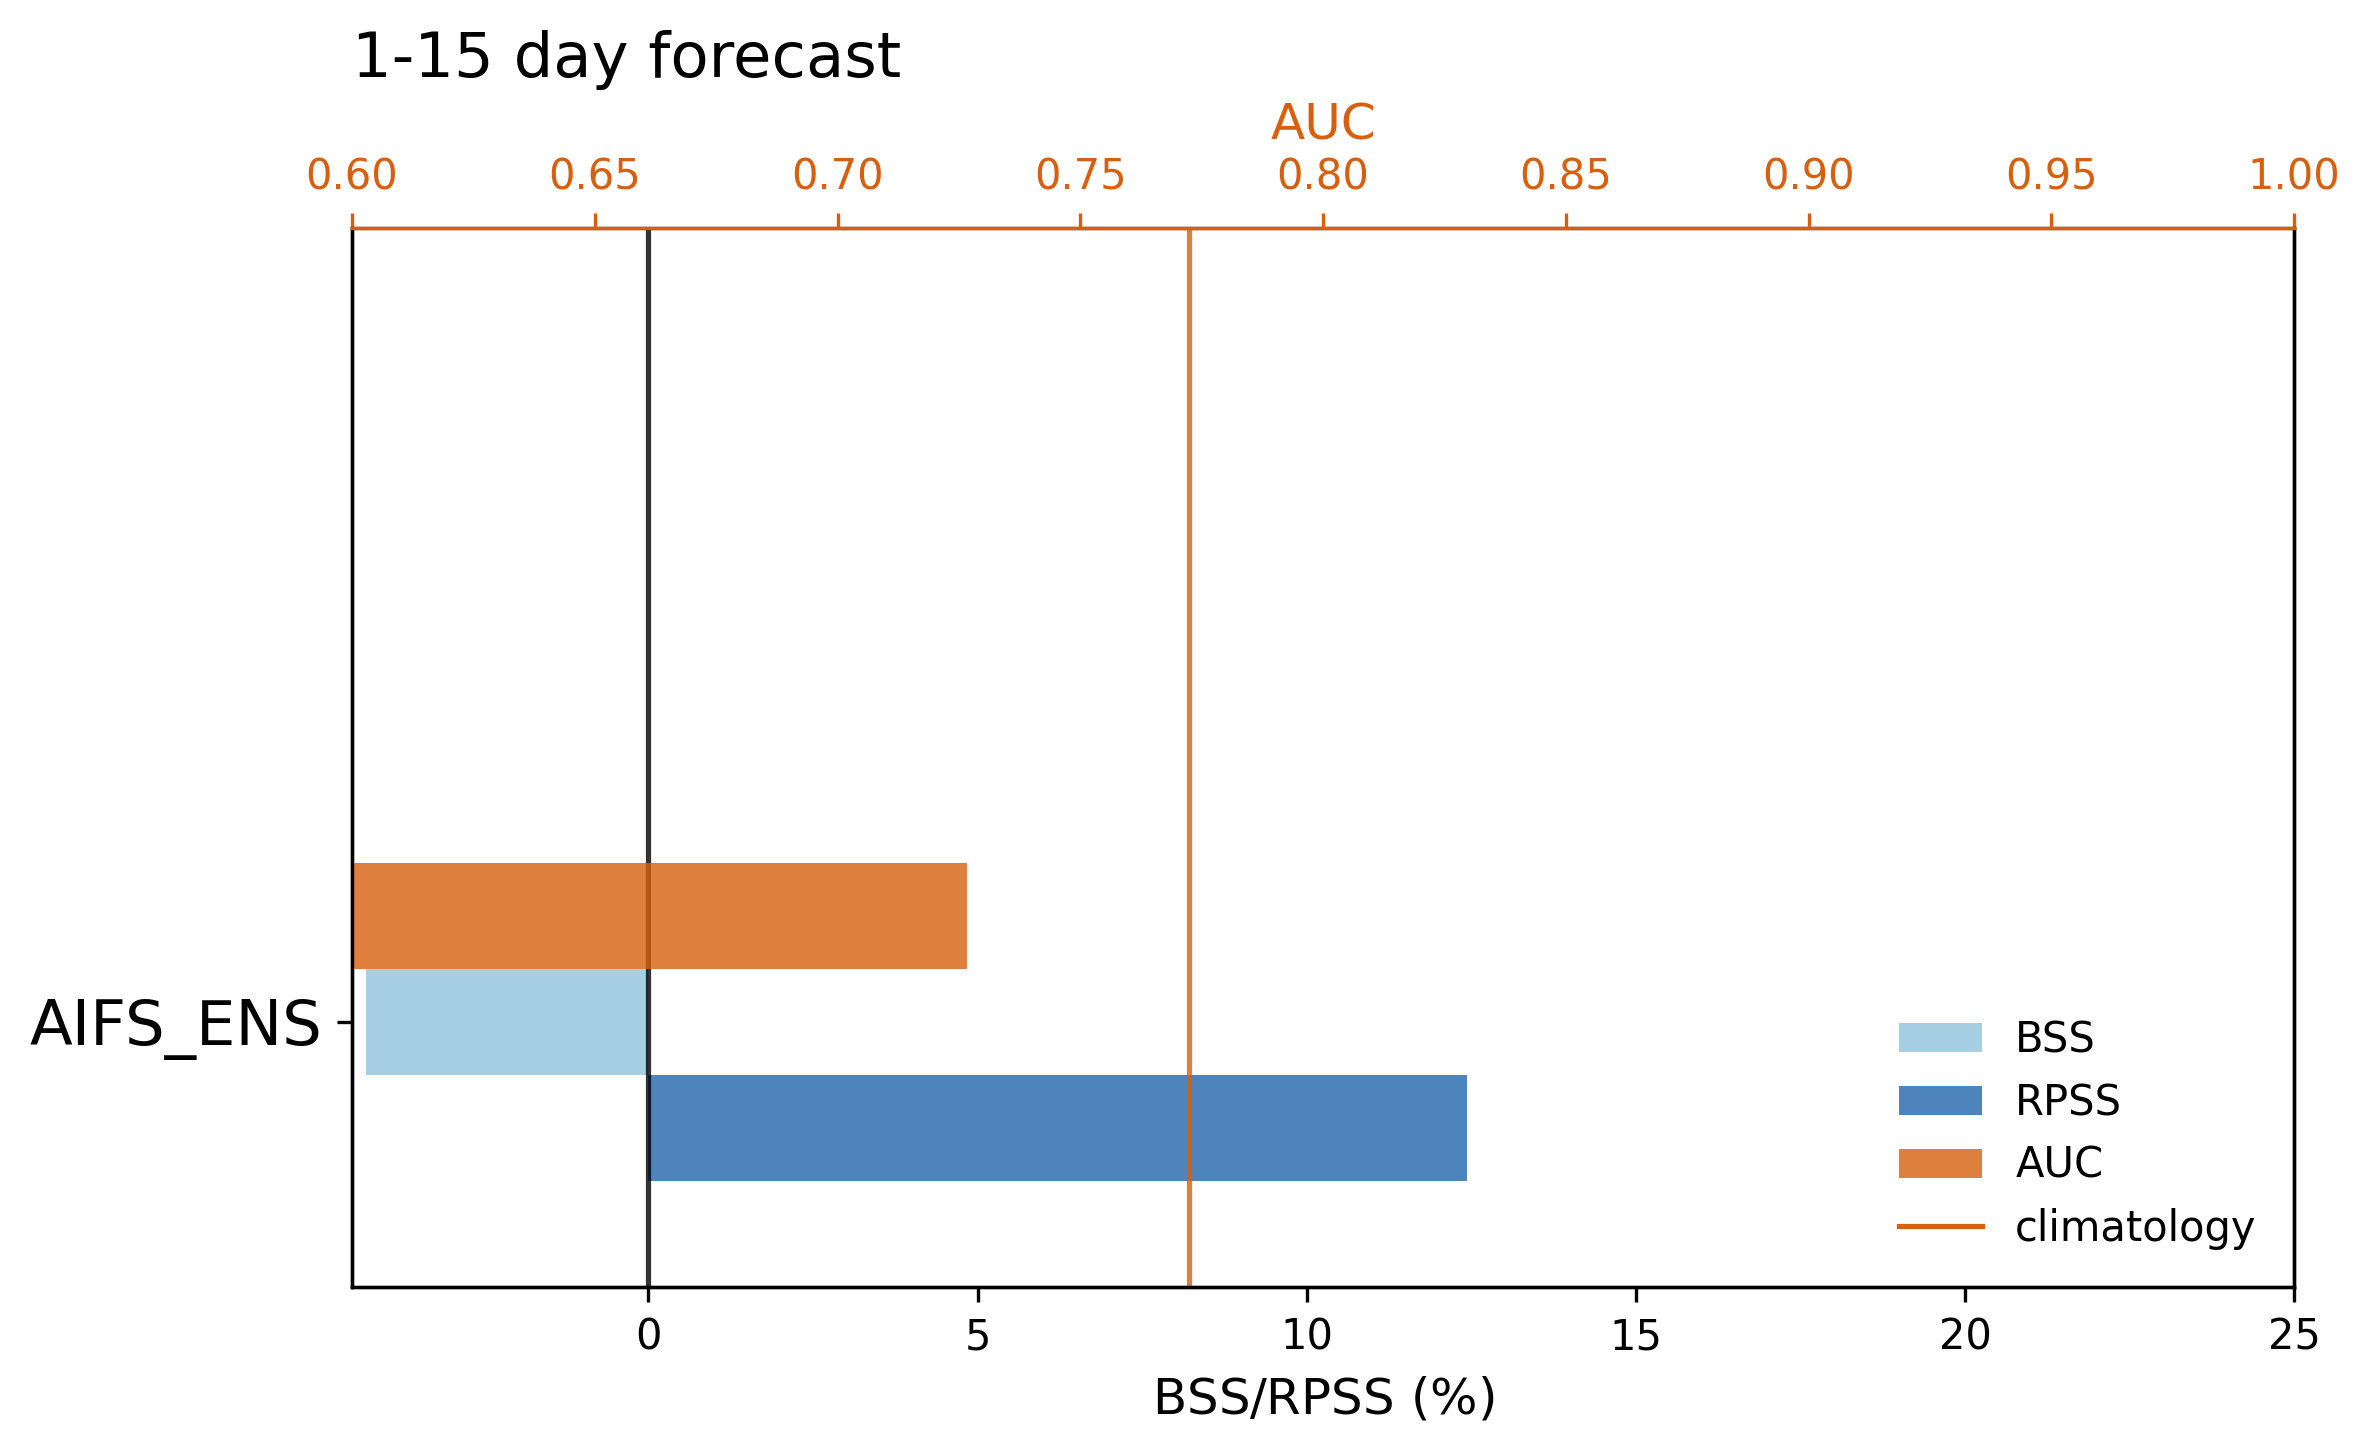

In [18]:
fig_filename = dir_fig_ens / f"panel_bar_BSS_RPSS_AUC_{tuple_to_str(window)}.png"
display(Image(filename=fig_filename, width=450))

<br>
<br>

RPSS (Ranked Probability Skill Score) is the grade for a "How Much/What Level" forecast. It is the industry standard for verifying multi-category probabilistic forecasts, such as seasonal outlooks (Below Normal, Near Normal, Above Normal) or rain intensity bins. RPSS cares about the distance between your prediction and reality.   

| RPSS Value | Interpretation | Operational Meaning |
| :--- | :--- | :--- |
| **1.0** | **Perfect Forecast** | You assigned 100% probability to the correct category every single time. |
| **> 0** | **Skilled** | Your model is "smarter" than just using the historical climate average. |
| **0** | **No Skill** | Your model is performing exactly as well as a "blind" climatology forecast. |
| **< 0** | **Worse than Climatology** | Your model is actively misleading; the historical average is a better guide. |

<br>

<br>

if `output.plot_panel_heatmap_skill` is `true`, it generates a heatmap of skill scores across models and forecast bins. it shows how forecast skill vary across different models, and different lead time.  

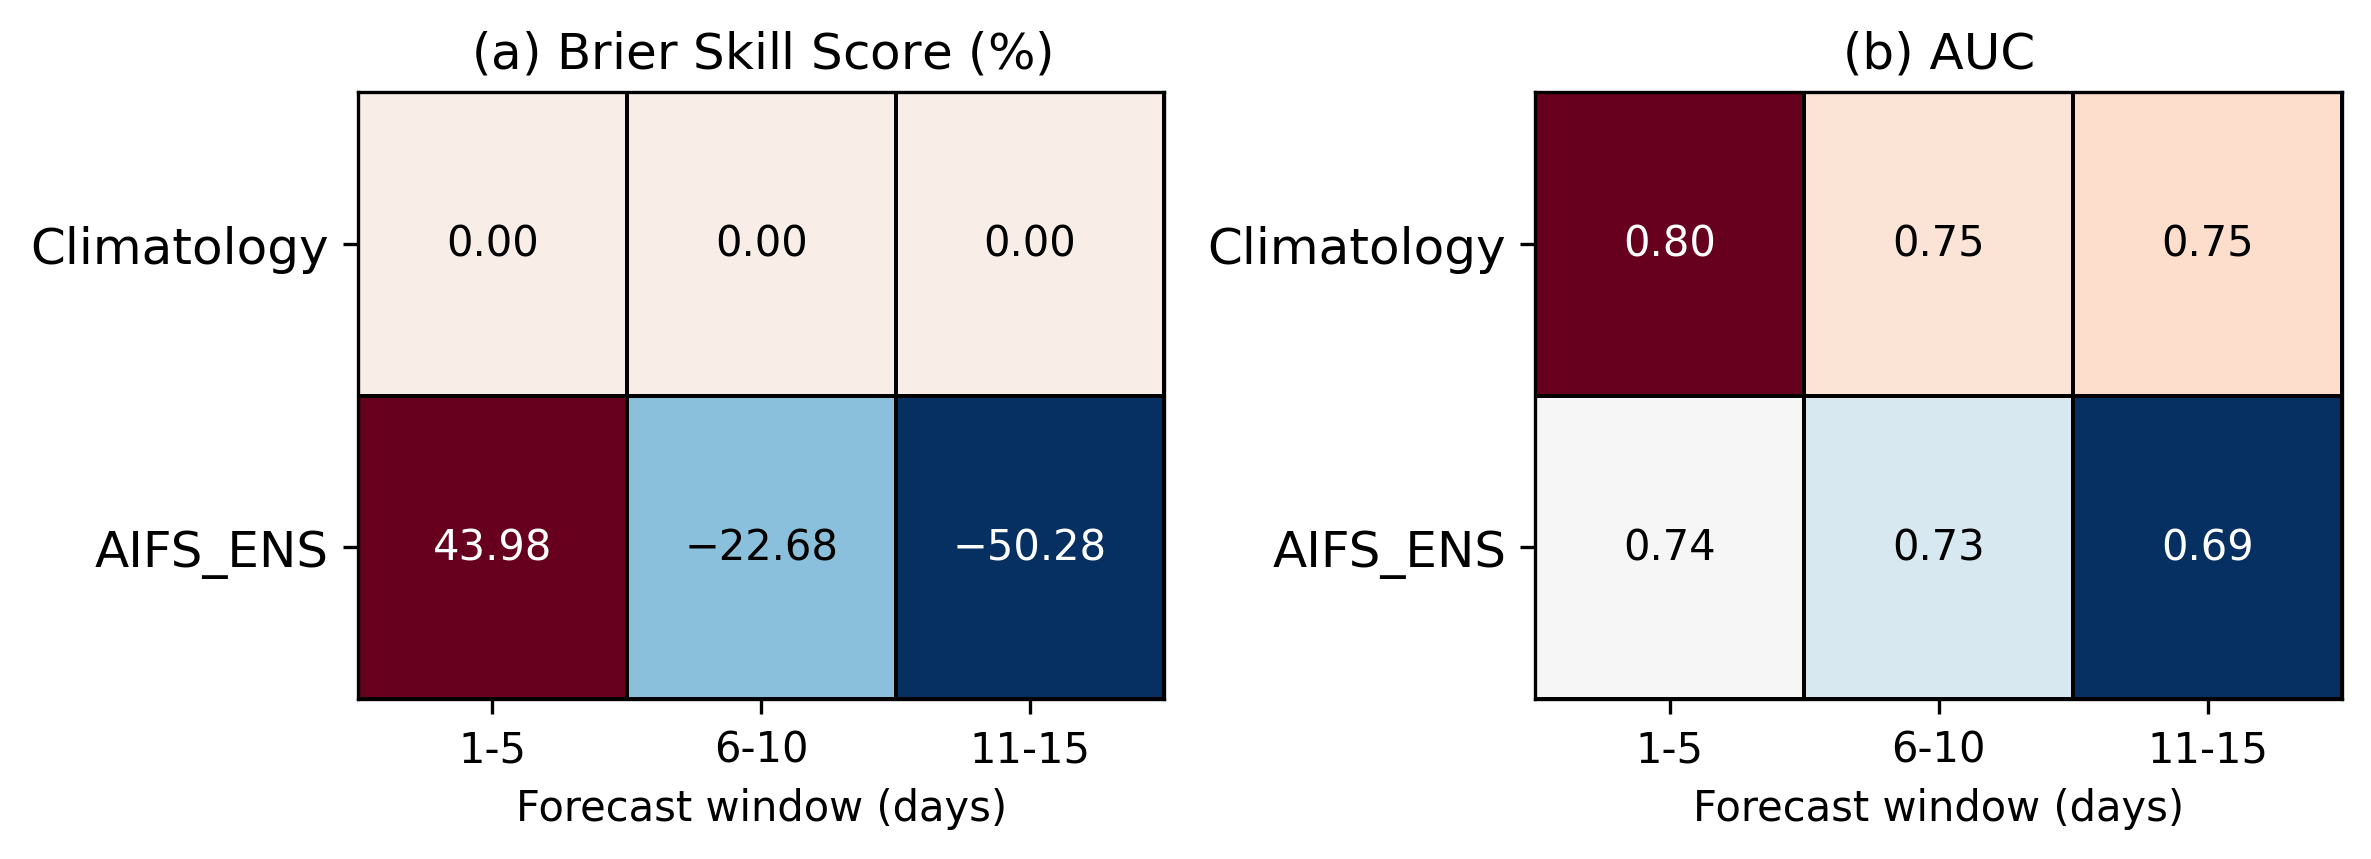

In [19]:
fig_filename = dir_fig_ens / f"panel_portrait_BSS_AUC_{tuple_to_str(window)}.png"
display(Image(filename=fig_filename, width=550))

<br>
<br>

For deterministic forecast, spatial metrics MAE, FAR, MR are saved in netcdf files

In [20]:
det_name = rc_det.models[0].name
filename = Path(rc_det.output.data_dir) / f"spatial_{det_name}_{tuple_to_str(window)}.nc"
print("loading saved metrics from", rel(filename))
ds = xr.open_dataset(filename)
ds

loading saved metrics from runs/ethiopia_icpac_2020_604e/scores/spatial_AIFS_1-15.nc


<xarray.Dataset> Size: 120kB
Dimensions:           (lat: 49, lon: 61)
Coordinates:
  * lat               (lat) float32 196B 3.0 3.25 3.5 3.75 ... 14.5 14.75 15.0
  * lon               (lon) float32 244B 33.0 33.25 33.5 ... 47.5 47.75 48.0
Data variables:
    false_alarm_rate  (lat, lon) float64 24kB ...
    miss_rate         (lat, lon) float64 24kB ...
    mean_mae          (lat, lon) float64 24kB ...
    mae_2020          (lat, lon) float64 24kB ...
    n_back_dated      (lat, lon) float64 24kB ...
Attributes:
    model:                AIFS
    years:                2020
    tolerance_days:       3
    verification_window:  1,15
    max_forecast_day:     15
    lead_window:          1,15
    n_back_dated_total:   178
    title:                Monsoon Onset MAE, FAR, MR Analysis
    description:          Spatial maps of Mean Absolute Error, False Alarm Ra...

<br>

an example of spatial error metrics plot

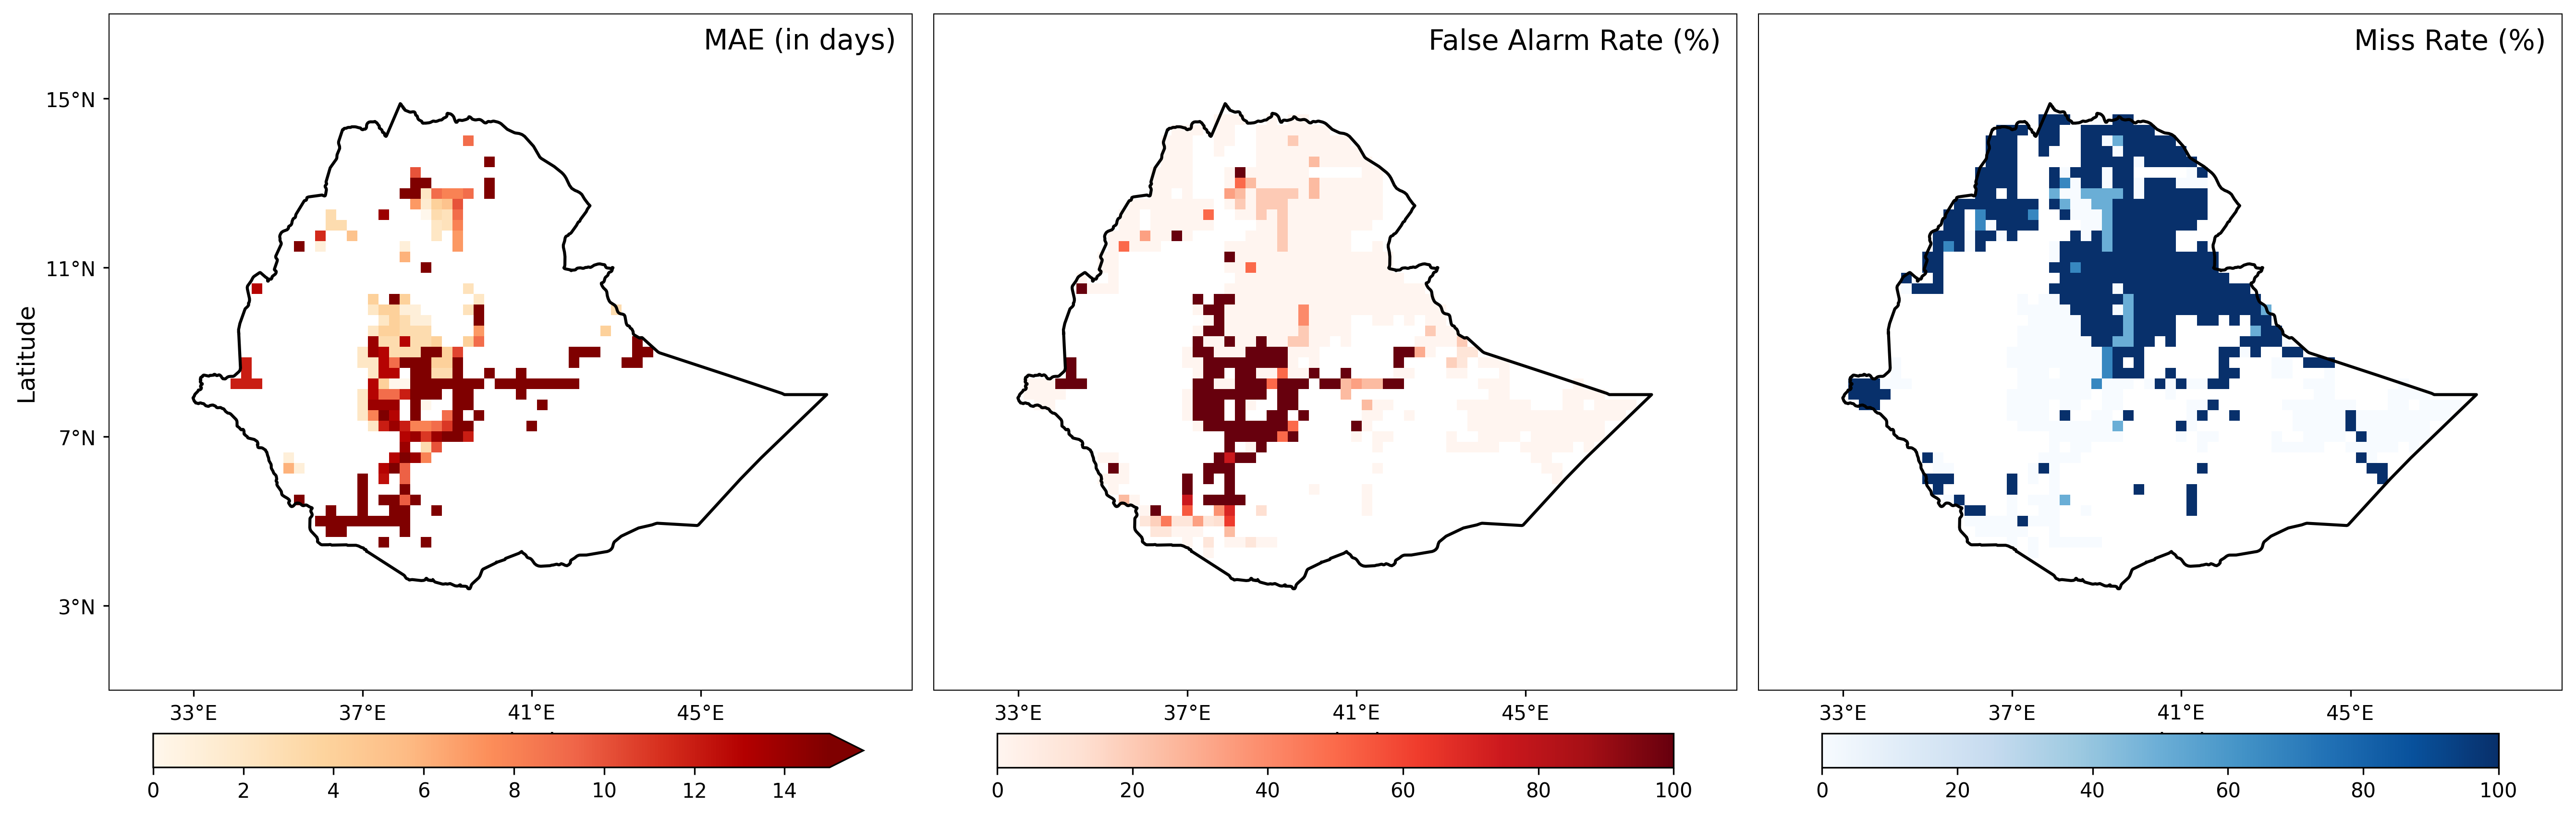

In [21]:
fig_filename = dir_fig_det / f"spatial_metrics_{det_name}_{tuple_to_str(window)}.png"
display(Image(filename=fig_filename, width=800))

<br>

In operational meteorology, these False Alarm Rate and Miss Rate are the "balancing act" of any forecast. They are derived from the Contingency Table (a 2x2 matrix of Hits, Misses, False Alarms, and True Negatives).   

Miss Rate (The "Asleep at the Wheel" Metric) is the proportion of actual events that were not forecasted. It is the mathematical complement of the Hit Rate (Probability of Detection). Operational Meaning: If your Miss Rate is 0.20, you missed 20% of the onsets that actually happened.  

False Alarm Rate (The "Crying Wolf" Metric) measures how often you forecast an event for days when nothing actually happens, relative to all the "quiet" days. Operational Meaning: It represents the probability that a "No" event will be incorrectly forecasted as a "Yes."   

The Operational Trade-off: There is a fundamental "tug-of-war" between these two. If you want a 0% Miss Rate, you could simply forecast "Rain" every single day. You would never miss a storm, but your False Alarm Rate would skyrocket. Conversely, if you want a 0% False Alarm Rate, you could never issue a warning at all. You'd never be wrong about a "Yes" forecast, but your Miss Rate would be 100%. Operational forecasting is the art of finding the "Sweet Spot" between these two extremes.  

| Metric | Goal | Operational Consequence of a High Score |
| :--- | :--- | :--- |
| **Miss Rate** | **0.0** | **Public Danger:** People are unwarned for a major event (e.g., a tornado with no siren). |
| **False Alarm Rate** | **0.0** | **Loss of Trust:** "The Boy Who Cried Wolf" effect. People ignore warnings because "it never happens anyway." |

<br>